# 0. Imports and defaults

As you work through this notebook, you will have to modify modules `model.py` and `preprocessing.py`. Whenever you do so, remember to: 
- Save the two modules after modifying them, then come back to this notebook;
- Restart the kernel in this notebook ->  ; 
- Rerun all cells in this section (0. Imports and defaults). 

This ensures that this notebook "sees" all the changes you implemented in the external modules and updates the corresponding function definitions. 

In [1]:
import pandas as pd
import numpy as np
import pylab as plt

import pypsa

# Import the public function from the package you completed
from energy_model import model_run

In [2]:
# Default parameters for testing

# input database folder
db_dir = 'input_databases//default'
db_dir_1 = 'input_databases//carbon_cap'

# model years
years = [2020,2030,2040,2050]

# intra-year temporal resolution
t_res = 15 # hours

# discount rates
rt = 0.07 # technical discount rate
rs = 0.01 # social discount rate

# passenger cars conversion factor
passenger_cars_cf = 40*0.1  # km/h

# NEW: subsidy growth 
subsidy_growth = 0.0

# NEW: demand parameters (insulation parameters)
K  = 0.9    # saturation: max share of highly insulated houses
s0 = 0.1    # share of highly insulated houses at t = 0
r  = 0.05   # growth rate
R  = 0.3    # demand reduction for highly insulated houses
T0 = 2000   # reference year, so t = model_year - 2000


In [3]:
# Handy plotting functions

def plot_main_ebs(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Residential electricity',
            'Residential heat',
            'Transportation',
            'Industrial machinery',
            'Industrial HTP']): 
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar',stacked='True', rot=0, colormap='tab20',ax=ax[n])
        if c=='Transportation':
            ax[n].set_ylabel('Mvkm')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)

    fig.tight_layout()

def plot_elc_emi(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Electricity','CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar',stacked='True', rot=0, colormap='tab20', ax=ax[n])

        if 'CO2' in c:
            ax[n].set_ylabel('tCO2')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1,-0.5))

    # Let's add cumulative CO2
    for n,c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax[n+3])
        ax[n+3].set_ylabel('tCO2')
        ax[n+3].set_title(f'Cumulative {c}')
        ax[n+3].legend(bbox_to_anchor=(1,-0.5))

    fig.tight_layout()


In [4]:
base = model_run(db_dir,years,t_res,passenger_cars_cf,rt,rs, subsidy_growth, K, s0, r, R, T0)
base.name = 'base'

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 416.41it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-mxes5lcv.lp
Reading time = 0.39 seconds
obj: 277489 rows, 129146 columns, 635313 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694848172e+20


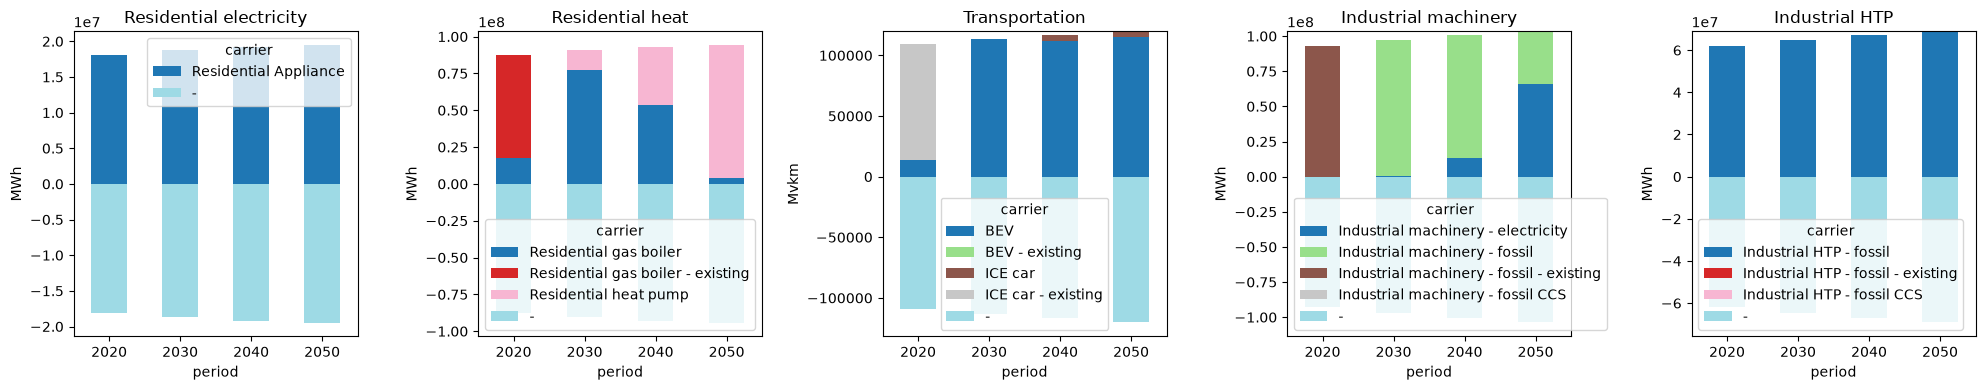

In [5]:
# Let's have a quick look at the demand-side energy balances:
plot_main_ebs(base)

/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/ipykernel_59958/992169818.py:48: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


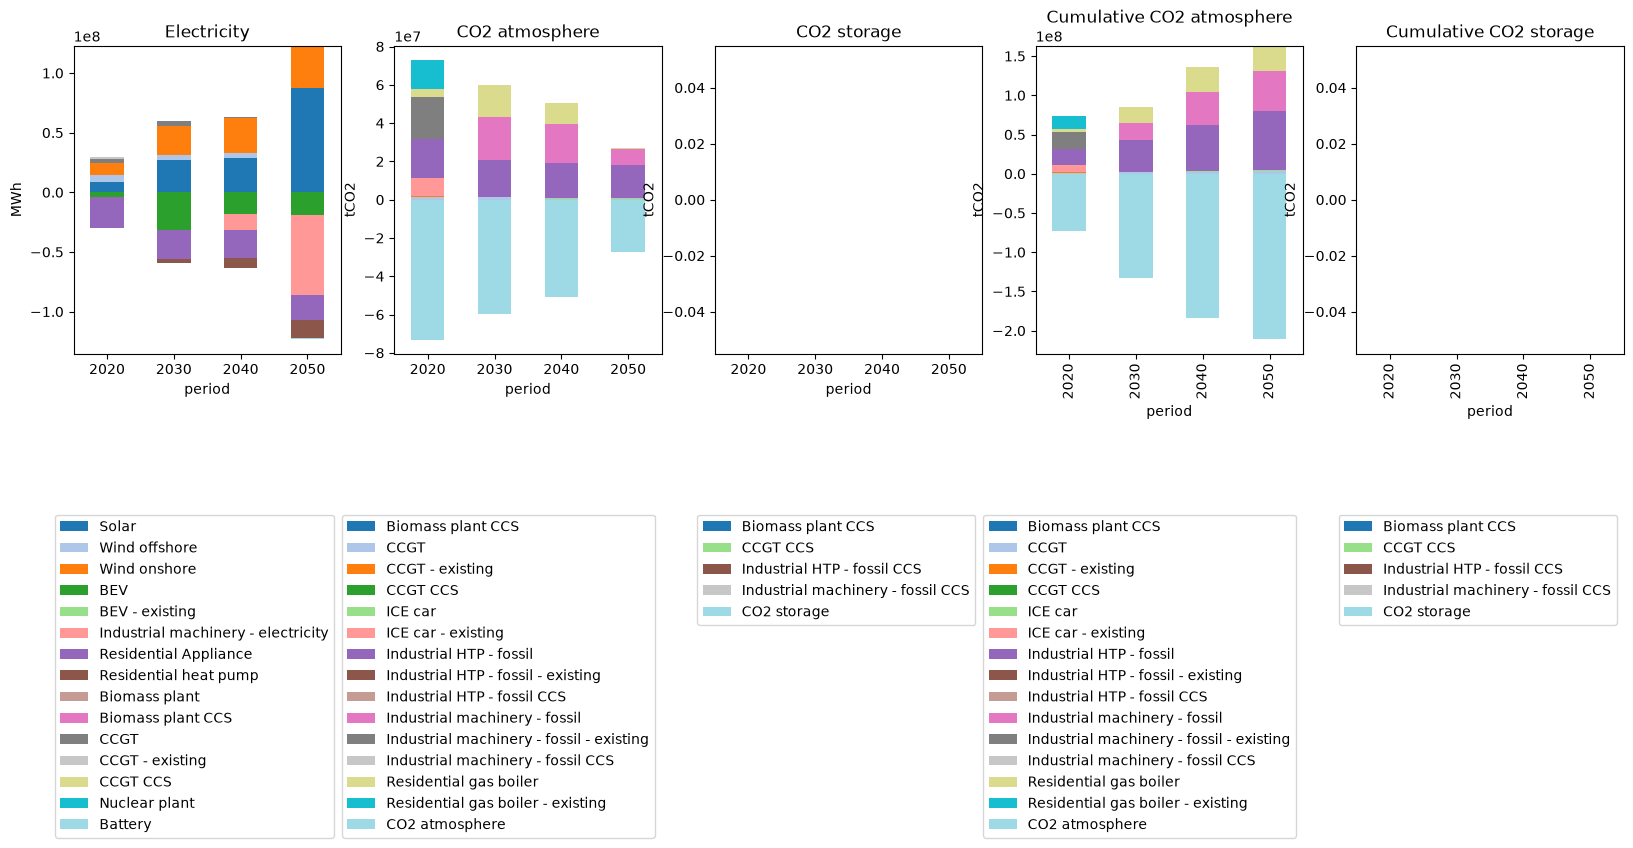

In [6]:
# Let's also look at electricity supply and emissions
plot_elc_emi(base)

As solar PV and wind energy become cheaper, from 2040 electricity naturally starts taking over large portions of passenger transportation, residential heat and industrial machinery. Industrial HTP remains fully fossil-fuel-based. Emissions naturally decrease, and in 2050 they are mostly due to industrial activity. The CO2 budget of 1 GtCO2 is not fully utilized.  

There are a couple of things happening in the model: 
- As wind and solar become cheaper, so does the average electricity price;
- Gas reserves ($10^9$ MWh) are fully depleted;
- As gas resources deplete its (shadow) price increases;
- Gasoline and CO2 reserves (resp $10^9$ MWh and 1 GtCO2) are by far not fully utilized, hence their (shadow) price remains 0.

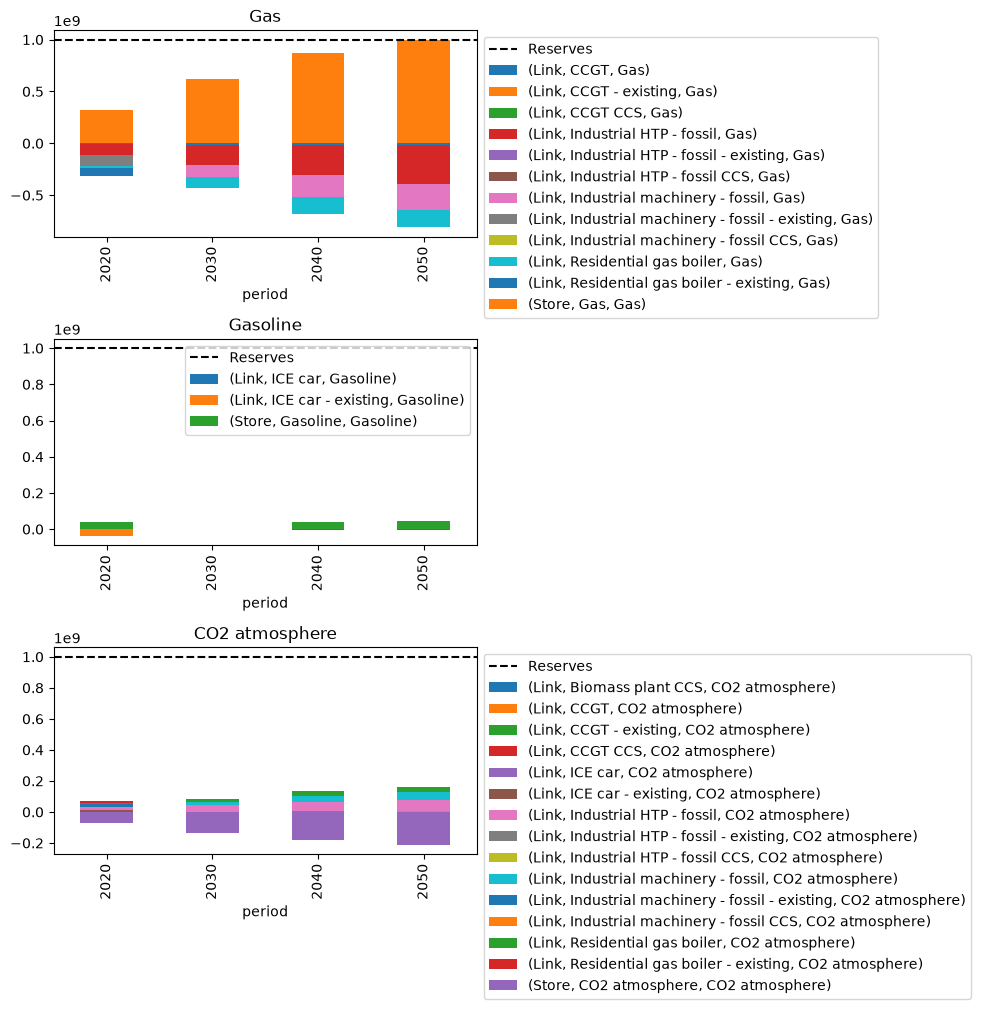

In [7]:
# Let's show that gas reserves are fully depleted by 2050, while gasoline reserves are not:
fig, ax = plt.subplots(3,1)
fig.set_size_inches(10,10)
reserves = {'Gas':1e9, 'Gasoline':1e9, 'CO2 atmosphere':1e9}
for n,c in enumerate(['Gas', 'Gasoline','CO2 atmosphere']):
    base.statistics.energy_balance(bus_carrier=c).cumsum(axis=1).T.plot(kind='bar', stacked=True, ax=ax[n])
    ax[n].hlines(reserves[c],-0.5,4.5, label='Reserves', ls='--', color='black')
    ax[n].legend(bbox_to_anchor=(1,1))
    ax[n].set_title(c)
plt.tight_layout()

In [8]:
# Show shadow prices of electricity, gas, gasoline and CO2 atmosphere
base.buses_t.marginal_price.groupby(level=0).agg('mean')[['Electricity','Gas supply','Gasoline supply','CO2 atmosphere']]

name,Electricity,Gas supply,Gasoline supply,CO2 atmosphere
period,,,,
2020,369.696422,31.912762,0.0,0.0
2030,222.582745,35.251543,0.0,0.0
2040,160.125626,38.939634,0.0,0.0
2050,132.906150,43.013581,0.0,0.0
